# Tasks - Lab 6


### Task 3.1: Compositional Featurization of Li-Ion Battery Cathodes

In [ ]:
# ==============================================================================
# TASK 3.1: COMPOSITIONAL FEATURIZATION
# ==============================================================================
import pandas as pd
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty

# 1. Create initial DataFrame with cathode formulas
cathode_formulas = ["LiCoO2", "LiFePO4", "LiMn2O4", "LiNiO2"]
df_cathodes = pd.DataFrame({"formula": cathode_formulas})

# 2. Convert formula strings to Pymatgen Composition objects
df_cathodes["composition"] = df_cathodes["formula"].apply(Composition)

print(f"Initial DataFrame shape: {df_cathodes.shape}")

# 3. Instantiate the Magpie ElementProperty featurizer
featurizer = ElementProperty.from_preset("magpie", impute_nan=True)

# 4. Featurize the DataFrame on the 'composition' column
df_cathodes_feat = featurizer.featurize_dataframe(
    df_cathodes, col_id="composition", ignore_errors=True
)

# 5. Inspect resulting shape and sample column names
print(f"Featurized DataFrame shape: {df_cathodes_feat.shape}")
print("\nSample generated column names (indices 10 to 19):")
print(df_cathodes_feat.columns[10:20].tolist())


# 6. Display selected physical descriptors
selected_cols = [
    "formula",
    "MagpieData mean Electronegativity",
    "MagpieData mean NdValence",
    "MagpieData mean CovalentRadius",
]
display(df_cathodes_feat[selected_cols].round(3))

### Task 3.2: High-Throughput API Ingestion & Featurization of Gold Binary Compounds

In [ ]:
# TASK 3.2: MATERIALS PROJECT INGESTION AND FEATURIZATION
# ==============================================================================
import os
import pandas as pd
from dotenv import load_dotenv
from mp_api.client import MPRester
from matminer.featurizers.composition import ElementProperty

load_dotenv()
API_KEY = os.getenv("MP_API_KEY")

# 1. Define target fields for server-side field projection
# Required: material_id, formula_pretty, composition, energy_above_hull
target_fields = [
    "material_id",
    "formula_pretty",
    "composition",
    "energy_above_hull",
]

# 2. Query Materials Project for stable binary compounds containing Gold (Au)
with MPRester(API_KEY) as mpr:
    docs_gold = mpr.materials.summary.search(
        elements=["Au"],
        num_elements=2,
        is_stable=True,
        fields=target_fields,
    )

print(f"Total raw gold binary records retrieved: {len(docs_gold)}")

# 3. Convert to DataFrame and deduplicate by ground-state stability
records = []
for doc in docs_gold:
    records.append(
        {
            "material_id": doc.material_id,
            "formula_pretty": doc.formula_pretty,
            "composition": doc.composition,
            "energy_above_hull": doc.energy_above_hull,
        }
    )

df_gold = (
    pd.DataFrame(records)
    .sort_values("energy_above_hull", ascending=True)
    .drop_duplicates(subset="formula_pretty", keep="first")
    .reset_index(drop=True)
)

print(
    f"Deduplicated ground-state gold binaries: {len(df_gold)} | Shape: {df_gold.shape}"
)

# 4. Instantiate Magpie featurizer and featurize 'composition' column
magpie = ElementProperty.from_preset("magpie", impute_nan=True)

df_gold_feat = magpie.featurize_dataframe(
    df_gold, col_id="composition", ignore_errors=True
)

print(f"Featurized DataFrame shape: {df_gold_feat.shape}")

# 5. Rank and display top 5 compounds by electronegativity range
display_cols = [
    "material_id",
    "formula_pretty",
    "MagpieData range Electronegativity",
    "MagpieData mean AtomicWeight",
]
display(
    df_gold_feat.sort_values("MagpieData range Electronegativity", ascending=False)[
        display_cols
    ].head(5)
)

### Task 3.3: Testing the "Packing vs. Atomic Mass" Hypothesis for Crystal Density

✓ Retrieved 250 SummaryDoc documents in 3.1s

Total raw stable ternary records retrieved: 250
Curated sample size for multi-scale featurization: 200


DensityFeatures: 100%|██████████| 200/200 [00:05<00:00, 37.04it/s] 



Correlation (Density vs. Mean Atomic Weight) : r = 0.743 (p = 2.22e-36)
Correlation (Density vs. Packing Fraction)   : r = 0.793 (p = 1.49e-44)


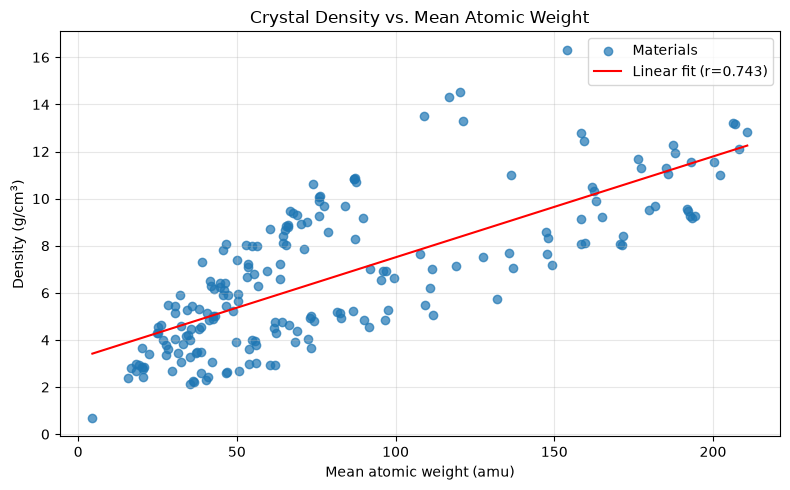

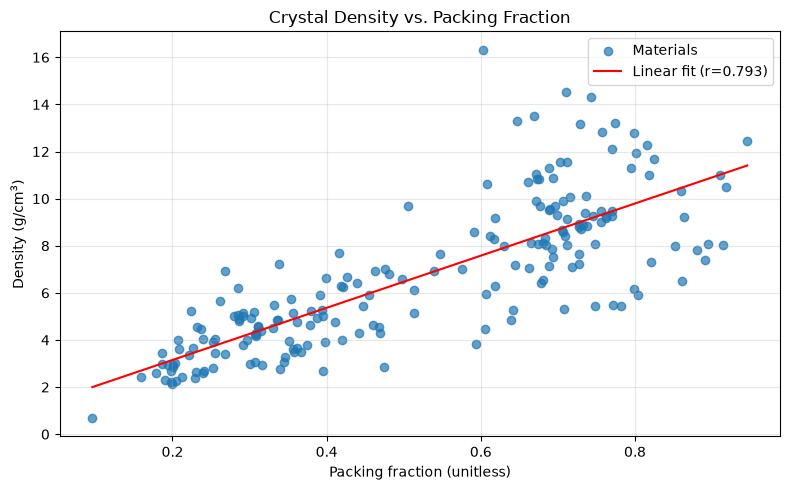

In [8]:
# ==============================================================================
# TASK 3.3: TESTING THE PACKING VS. ATOMIC MASS HYPOTHESIS
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from dotenv import load_dotenv
from mp_api.client import MPRester
from scipy import stats
from matminer.featurizers.composition import ElementProperty
from matminer.featurizers.structure import DensityFeatures

# 1. Define target fields for projection
target_fields = [
    "material_id",
    "formula_pretty",
    "density",
    "composition",
    "structure",
    "energy_above_hull",
]

load_dotenv()
API_KEY = os.getenv("MP_API_KEY")

# 2. Query stable ternary compounds from Materials Project (limited chunk for speed)
with MPRester(API_KEY) as mpr:
    # Query stable ternary materials from the summary endpoint
    #       chunk_size=250, num_chunks=1, and fields=target_fields
    docs_ternary = mpr.materials.summary.search(
        num_elements=3,
        is_stable=True,
        chunk_size=250,
        num_chunks=1,
        fields=target_fields,
    )

print(f"Total raw stable ternary records retrieved: {len(docs_ternary)}")

# 3. Tabularize, rename 'density' -> 'mp_density', deduplicate formulas, and slice 200 rows
records = [
    {
        "material_id": doc.material_id,
        "formula_pretty": doc.formula_pretty,
        "mp_density": doc.density,  # Renamed to avoid collision with DensityFeatures()
        "composition": doc.composition,
        "structure": doc.structure,
        "energy_above_hull": doc.energy_above_hull,
    }
    for doc in docs_ternary
]

# : Create DataFrame, dropna on ['mp_density', 'structure'], sort by 'energy_above_hull',
#       drop duplicates on 'formula_pretty', and select .head(200)
df_ml = pd.DataFrame(records)
df_ml = (
    df_ml.dropna(subset=["mp_density", "structure"])
    .sort_values("energy_above_hull")
    .drop_duplicates(subset="formula_pretty")
    .head(200)
    .reset_index(drop=True)
)

print(f"Curated sample size for multi-scale featurization: {len(df_ml)}")

# 4. Generate Compositional (Magpie) and Structural (DensityFeatures) descriptors
# : Instantiate ElementProperty.from_preset("magpie", impute_nan=True) and featurize 'composition'
magpie = ElementProperty.from_preset("magpie", impute_nan=True)
df_ml = magpie.featurize_dataframe(df_ml, col_id="composition", ignore_errors=True)

# : Instantiate DensityFeatures() and featurize 'structure' (ignore_errors=True)
density_feat = DensityFeatures()
df_ml = density_feat.featurize_dataframe(df_ml, col_id="structure", ignore_errors=True)

# Drop any rows with NaN generated during structural featurization
df_ml = df_ml.dropna(
    subset=["MagpieData mean AtomicWeight", "packing fraction"]
).reset_index(drop=True)

# 5. Compute Pearson correlation statistics using scipy.stats.pearsonr
# : Compute (r_mass, p_mass) and (r_pack, p_pack) against 'mp_density'
r_mass, p_mass = stats.pearsonr(
    df_ml["mp_density"], df_ml["MagpieData mean AtomicWeight"]
)
r_pack, p_pack = stats.pearsonr(df_ml["mp_density"], df_ml["packing fraction"])

print(
    f"\nCorrelation (Density vs. Mean Atomic Weight) : r = {r_mass:.3f} (p = {p_mass:.2e})"
)
print(
    f"Correlation (Density vs. Packing Fraction)   : r = {r_pack:.3f} (p = {p_pack:.2e})"
)

# 6. Sequential Single-Figure Visualizations (Pure Matplotlib)

# --- Plot 1: mp_density vs. MagpieData mean AtomicWeight ---
plt.figure(figsize=(8, 5))
x_mass = df_ml["MagpieData mean AtomicWeight"]
y_density = df_ml["mp_density"]
plt.scatter(x_mass, y_density, alpha=0.7, label="Materials")
mass_fit_x = np.linspace(x_mass.min(), x_mass.max(), 100)
mass_fit_y = np.polyval(np.polyfit(x_mass, y_density, 1), mass_fit_x)
plt.plot(mass_fit_x, mass_fit_y, color="red", label=f"Linear fit (r={r_mass:.3f})")
plt.title("Crystal Density vs. Mean Atomic Weight")
plt.xlabel("Mean atomic weight (amu)")
plt.ylabel("Density (g/cm$^3$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Plot 2: mp_density vs. packing fraction ---
plt.figure(figsize=(8, 5))
x_packing = df_ml["packing fraction"]
plt.scatter(x_packing, y_density, alpha=0.7, label="Materials")
packing_fit_x = np.linspace(x_packing.min(), x_packing.max(), 100)
packing_fit_y = np.polyval(np.polyfit(x_packing, y_density, 1), packing_fit_x)
plt.plot(
    packing_fit_x,
    packing_fit_y,
    color="red",
    label=f"Linear fit (r={r_pack:.3f})",
)
plt.title("Crystal Density vs. Packing Fraction")
plt.xlabel("Packing fraction (unitless)")
plt.ylabel("Density (g/cm$^3$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Task 3.4 (*): Electronic vs. Structural Drivers in II–VI


✓ Retrieved 177 SummaryDoc documents in 2.1s

Total II-VI polymorph records retrieved: 177
Cleaned polymorph records: 177


StructuralHeterogeneity: 100%|██████████| 177/177 [00:06<00:00, 26.48it/s] 



--- Correlation Matrix (II-VI Semiconductors) ---


,band_gap,MagpieData mean Electronegativity,density,mean absolute deviation in relative bond length
band_gap,1.000,-0.065,-0.377,-0.460
MagpieData mean Electronegativity,-0.065,1.000,0.128,0.086
density,-0.377,0.128,1.000,-0.435
mean absolute deviation in relative bond length,-0.460,0.086,-0.435,1.000


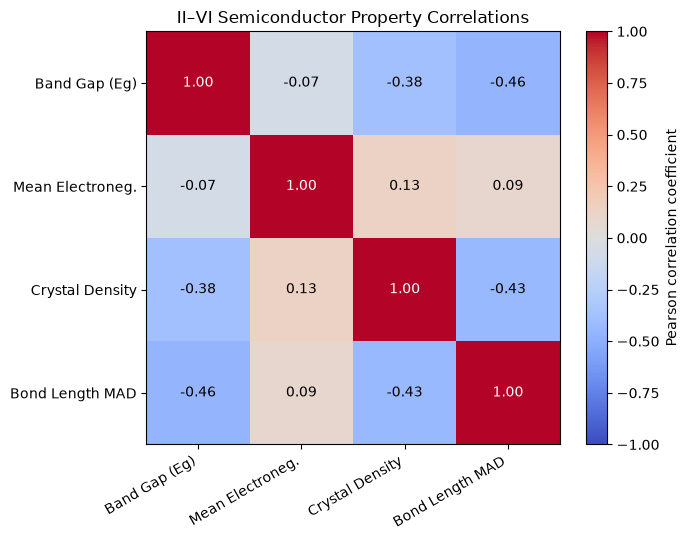

In [9]:
# ==============================================================================
# TASK 3.4 (*): STUDENT STARTER CODE
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mp_api.client import MPRester
from matminer.featurizers.composition import ElementProperty
from matminer.featurizers.structure import DensityFeatures, StructuralHeterogeneity

# 1. Define target formulas and field projection
target_formulas = ["ZnS", "ZnO", "CdS", "CdSe", "CdTe"]
target_fields = [
    "material_id",
    "formula_pretty",
    "composition",
    "structure",
    "band_gap",
    # : Specify material_id, formula_pretty, composition, structure, band_gap
]

# 2. Query Materials Project for all polymorphs of the target II-VI semiconductors
with MPRester(API_KEY) as mpr:
    docs_ii_vi = mpr.materials.summary.search(
        formula=target_formulas, fields=target_fields
    )

print(f"Total II-VI polymorph records retrieved: {len(docs_ii_vi)}")

# 3. Convert to DataFrame and drop rows missing 'band_gap' or 'structure'
records = [
    {
        "material_id": doc.material_id,
        "formula_pretty": doc.formula_pretty,
        "composition": doc.composition,
        "structure": doc.structure,
        "band_gap": doc.band_gap,
    }
    for doc in docs_ii_vi
]

# : Construct df_semiconductors, dropna on ['band_gap', 'structure'], and reset index
df_semiconductors = (
    pd.DataFrame(records)
    .dropna(subset=["band_gap", "structure"])
    .reset_index(drop=True)
)

print(f"Cleaned polymorph records: {len(df_semiconductors)}")

# 4. Multi-scale featurization: Magpie + DensityFeatures + StructuralHeterogeneity
# : Featurize 'composition' with ElementProperty.from_preset("magpie", impute_nan=True)
magpie = ElementProperty.from_preset("magpie", impute_nan=True)
df_semiconductors = magpie.featurize_dataframe(
    df_semiconductors, col_id="composition", ignore_errors=True
)

# : Featurize 'structure' with DensityFeatures() (ignore_errors=True)
density_feat = DensityFeatures()
df_semiconductors = density_feat.featurize_dataframe(
    df_semiconductors, col_id="structure", ignore_errors=True
)

# : Featurize 'structure' with StructuralHeterogeneity() (ignore_errors=True)
het_feat = StructuralHeterogeneity()
df_semiconductors = het_feat.featurize_dataframe(
    df_semiconductors, col_id="structure", ignore_errors=True
)

# 5. Isolate 4 target variables and compute Pearson correlation matrix
corr_cols = [
    "band_gap",
    "MagpieData mean Electronegativity",
    "density",
    "mean absolute deviation in relative bond length",
]
# : Create df_corr = df_semiconductors[corr_cols].dropna() and compute corr_matrix = df_corr.corr()
df_corr = df_semiconductors[corr_cols].dropna()
corr_matrix = df_corr.corr()

print("\n--- Correlation Matrix (II-VI Semiconductors) ---")
display(corr_matrix.round(3))

# 6. Visualize Correlation Heatmap in Pure Matplotlib (ZERO seaborn)
short_labels = [
    "Band Gap (Eg)",
    "Mean Electroneg.",
    "Crystal Density",
    "Bond Length MAD",
]

plt.figure(figsize=(7, 5.5))
image = plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0)
plt.colorbar(image, label="Pearson correlation coefficient")
plt.xticks(range(len(short_labels)), short_labels, rotation=30, ha="right")
plt.yticks(range(len(short_labels)), short_labels)
for row in range(len(short_labels)):
    for col in range(len(short_labels)):
        value = corr_matrix.iloc[row, col]
        text_color = "white" if abs(value) >= 0.6 else "black"
        plt.text(col, row, f"{value:.2f}", ha="center", va="center", color=text_color)
plt.title("II–VI Semiconductor Property Correlations")
plt.tight_layout()
plt.show()